# 01 · Load & Clean: and what problem we're actually solving

**Project:** Non-contractual customer value with ML (UCI Online Retail II)
**This notebook:** frames the project, then turns ~1.07M raw invoice lines into a clean purchase table where **every row removed is a logged, defensible decision**.

---

## Part A: Problem framing (read this before any code)

### The business
A UK online gift and homeware shop, Dec 2009 to Dec 2011. Many customers are **small retailers buying wholesale**
(orders of 12, 24, sometimes thousands of units), alongside ordinary consumers. Revenue is very concentrated and very seasonal (Christmas stock).

### Why "non-contractual" changes everything
| | Contractual (Netflix, gym) | **Non-contractual (this shop, ARQ)** |
|---|---|---|
| How customers leave | They cancel, **observed** | They just **go quiet** |
| Churn label | Exists, with a date | **Never observed** |
| Natural question | *When* will they cancel? | *Will they buy again, and how much?* |

A customer silent for 4 months could be gone for good, or could be a wholesaler restocking right on schedule.
We **can't label anyone "churned"**, so we predict **observable future behaviour over a fixed window** instead.

### The goal
> **For each customer, standing on a cutoff date and using only their history up to that date, predict their next 6 months:**
>
> | Target | Type | Question |
> |---|---|---|
> | `y_buy` | classification (0/1) | Will they purchase at all in the next 6 months? |
> | `y_spend` | regression (£) | How much will they spend? (zero-inflated, heavy-tailed) |
> | `y_ltv` | `y_spend × 30%` | How much **margin** is that worth? (30% is an *assumption*: the data has revenue only) |

**Unit of prediction:** one customer at one cutoff date. **Who is scored:** only customers with ≥1 purchase before the cutoff (no cold start).

**Why 6 months instead of "lifetime"?** We can *validate* it (we observe the next 6 months), it matches how retention budgets are planned, and it avoids extrapolating years ahead from two years of data.
So "LTV" in this project means **6-month forward value**, stated explicitly.

### The real question behind the goal
> *Can we predict this, and **which modeling choices actually matter** for getting it right?*

Every later notebook is a controlled comparison: model vs. naive baseline ("next 6 months = last 6 months"), log1p vs. Tweedie vs. two-stage hurdle, one-hot vs. target encoding, honest vs. leaky pipeline.
A model "wins" only if it beats the alternative **by more than noise** (bootstrap CIs).

### The decision it drives
- **Retention targeting:** offer incentives to **high-value customers at risk**, not loyal ones who'd buy anyway (wasted discount) or low-value ones (not worth it).
- **CAC caps:** if a customer like X is worth £200 margin over 6 months, don't pay more than that to acquire one.
- **Forecasting:** expected revenue from the existing base.

**ARQ mapping:** purchase ≈ FX conversion / card swipe; spend ≈ FX volume or interchange; wholesale skew ≈ a few high-volume users driving most revenue.

### The design rule that governs everything: no peeking at the future
Features use **only data on or before the cutoff**. Validation is **time-based** (validation cutoff 2010-12-09; test cutoff 2011-06-09, touched once in notebook 12).
Leakage gives you great offline metrics and a useless production model, so it gets its own notebook (11).

### Roadmap
`01 clean` → `02 EDA` → `03 framing & split + baselines` → `04 features` → `05 preprocessing` → `06 buy-again classifier` → `07 spend regression` → `08 tuning` → `12 final test`
(then 11 leakage demo, 09 NN vs GBM, 10 clustering)

---

## Part B: This notebook

**Question:** which raw rows represent *real customer demand that we can attribute to a customer*?

Cleaning is not a chore before the modeling. **It defines the population and the target.** Every rule here changes what "spend" means and which customers exist, so each rule gets:
*what it removes → why → the alternative we didn't pick → what bias it introduces.*

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent))
from src.clean import (load_raw, clean, is_non_product, is_cancellation,
                       find_immediate_reversals, CLEAN_PARQUET, RETURNS_PARQUET)

pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 90)
SEED = 42
np.random.seed(SEED)

## 1. Load (once from xlsx, then from a parquet cache)
Reading the 45MB xlsx takes minutes; parquet takes about a second. `load_raw()` reads both sheets (2009-10, 2010-11) once, concatenates them, and caches the result.

In [2]:
raw = load_raw()
print(f"{len(raw):,} rows × {raw.shape[1]} columns")
print("Date range:", raw["InvoiceDate"].min(), "→", raw["InvoiceDate"].max())
raw.head()

1,067,371 rows × 8 columns
Date range: 2009-12-01 07:45:00 → 2011-12-09 12:50:00


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [3]:
pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing_share": raw.isna().mean().round(4),
    "n_unique": raw.nunique(),
})

,dtype,missing_share,n_unique
Invoice,object,0.0000,53628
StockCode,object,0.0000,5305
Description,string,0.0041,5698
Quantity,int64,0.0000,1057
InvoiceDate,datetime64[ns],0.0000,47635
Price,float64,0.0000,2807
Customer ID,float64,0.2277,5942
Country,string,0.0000,43


**Takeaway:** 2 years and 8 days of data. **About 23% of rows have no Customer ID.** Description is missing for a small number of rows (irrelevant: we key on StockCode).

### 🧠 Predict before we clean
1. Which single rule will remove the most rows? Which will remove the most **revenue**?
2. Rows with no Customer ID: who are they, and how might their orders differ from identified customers'?
3. The largest single line in the data is 80,995 units of a £2 paper craft item. Real wholesale order or something else?

## 2. The issues, one at a time (inspect *before* filtering)

### 2a. Missing Customer ID: who are these people?
We **must** drop them: without an ID there's no customer history and no target. But the question is what population we're left with.

In [4]:
has_id = raw["Customer ID"].notna()
lines = raw.assign(line_value=raw["Quantity"] * raw["Price"], has_id=has_id)
inv = (lines[lines["Quantity"] > 0]
       .groupby(["has_id", "Invoice"])
       .agg(order_value=("line_value", "sum"), n_lines=("StockCode", "size"),
            uk=("Country", lambda c: (c == "United Kingdom").mean())))
inv.groupby("has_id").agg(
    invoices=("order_value", "size"),
    median_order_value=("order_value", "median"),
    median_lines_per_order=("n_lines", "median"),
    share_uk=("uk", "mean"),
).round(2)

,invoices,median_order_value,median_lines_per_order,share_uk
has_id,,,,
False,4969,10.92,2.0,0.98
True,36975,305.22,15.0,0.91


**Takeaway:** anonymous invoices look nothing like identified ones: a **median order of about £11 with 2 lines vs. about £305 with 15 lines**, and 98% UK.
They look like small guest checkouts by consumers. Identified invoices look like trade and wholesale orders.

**Bias:** the model describes **identified (account-holding) customers**, who skew toward repeat and wholesale buyers.
Retention rates and LTV estimates will be **higher** than for the true full customer base.
**ARQ analogy:** small concern there, since every fintech user is KYC'd and identified. But the analogous trap is training only on users who completed onboarding and then scoring everyone.

### 2b. Non-product StockCodes

In [5]:
codes = raw["StockCode"].astype(str)
np_mask = is_non_product(raw["StockCode"])
(raw[np_mask]
 .assign(code=codes[np_mask], value=raw["Quantity"] * raw["Price"])
 .groupby("code")
 .agg(rows=("code", "size"), example=("Description", "first"), total_value=("value", "sum"))
 .sort_values("rows", ascending=False)
 .round(0)
 .head(15))

,rows,example,total_value
code,,,
POST,2122,POSTAGE,112341.0
DOT,1446,DOTCOM POSTAGE,322647.0
M,1421,Manual,-82796.0
C2,282,CARRIAGE,13386.0
D,177,Discount,-13485.0
S,104,SAMPLES,-6066.0
BANK CHARGES,102,Bank Charges,-35563.0
ADJUST,67,Adjustment by john on 26/01/2010 16,6835.0
AMAZONFEE,43,AMAZON FEE,-260764.0


**Takeaway:** postage (POST, DOT), manual entries (M), bank and Amazon fees, bad-debt adjustments (B), samples (S) and gift vouchers.
None of these is a customer *wanting a product*.

- **Why remove:** postage scales with order size, so it would double-count demand. Manual adjustments and bad debt are accounting entries.
- **Alternative not picked:** keep postage as part of "revenue". Defensible if the business question were *total cash collected*, but our question is product demand.
- **Note:** `DCGS…` codes look odd but are real products (party bags, gum), so we keep them.

### 2c. Cancellations: returns, not purchases
Invoices starting with **C** have negative quantities. They aren't purchases, but **they carry signal**: a customer who returns a lot is worth less than their gross spend suggests.
So we **set them aside** (for a return-rate feature in notebook 04) instead of throwing them away.

In [6]:
cancel = is_cancellation(raw["Invoice"])
print(f"Cancellation lines: {cancel.sum():,} ({cancel.mean():.1%} of rows)")
print("Quantity sign on cancellation lines:", np.sign(raw.loc[cancel, "Quantity"]).value_counts().to_dict())

Cancellation lines: 19,494 (1.8% of rows)
Quantity sign on cancellation lines: {-1: 19493, 1: 1}


### 2d. The biggest "orders" in the data are not orders

In [7]:
biggest = (raw.assign(value=raw["Quantity"] * raw["Price"])
              .query("Quantity > 0 and `Customer ID`.notna()")
              .nlargest(2, "value"))
cols = ["Invoice", "StockCode", "Description", "Quantity", "Price", "Customer ID", "InvoiceDate"]
for _, row in biggest.iterrows():
    same = raw[(raw["Customer ID"] == row["Customer ID"]) & (raw["StockCode"] == row["StockCode"])
               & (raw["Quantity"].abs() == row["Quantity"])]
    display(same[cols])

,Invoice,StockCode,Description,Quantity,Price,Customer ID,InvoiceDate
1065882,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,16446.0,2011-12-09 09:15:00
1065883,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2.08,16446.0,2011-12-09 09:27:00


,Invoice,StockCode,Description,Quantity,Price,Customer ID,InvoiceDate
587080,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,12346.0,2011-01-18 10:01:00
587085,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,1.04,12346.0,2011-01-18 10:17:00


**Takeaway:** the two largest purchase lines (£168k and £77k) were **cancelled 12–16 minutes later**: the same customer, product, quantity and price.
These are order-entry mistakes. If we just drop the cancellations and keep the purchases, these two errors become the two "most valuable" purchases in the data and **distort any spend target**.

**Rule:** a purchase line cancelled **exactly** (same customer, StockCode, Price, |Quantity|) **within 24h** is an entry error, so we drop **both** lines.
- **Why 24h:** a correction made the same day is a mistake being fixed. A cancellation weeks later is a real return, a behaviour we want to measure, so those stay as returns.
- **Alternative not picked:** net *all* cancellations against their original purchases. More "correct" in accounting terms, but matching is ambiguous (partial returns, different prices).
  It also creates a **leakage trap**: a return that happens *after* a cutoff would reduce spend *before* the cutoff. With a 24h window this cross-cutoff effect is negligible.
- **Assumption:** exact-match plus same-day means error. A real same-day return of a full line would also be removed. That's rare, and dropping it barely changes the customer's value either way.

Let's see how much this matters across the whole dataset:

In [8]:
# Pre-filter the same way clean() does, so the comparison is apples to apples
base = raw.drop_duplicates()
base = base[base["Customer ID"].notna() & ~is_non_product(base["StockCode"]) & (base["Price"] > 0)]
base = base.assign(**{"Customer ID": base["Customer ID"].astype(int)})
c_mask = is_cancellation(base["Invoice"])
pur, ret = base[~c_mask & (base["Quantity"] > 0)], base[c_mask]

rows = []
for h in [1, 24, 24 * 7, 24 * 30]:
    pairs = find_immediate_reversals(pur, ret, max_hours=h)
    rows.append({"window_hours": h, "lines_matched": len(pairs),
                 "spend_removed_£": (pur.loc[pairs["purchase_idx"], "Quantity"]
                                    * pur.loc[pairs["purchase_idx"], "Price"]).sum()})
sens = pd.DataFrame(rows)
sens["share_of_total_spend"] = sens["spend_removed_£"] / (pur["Quantity"] * pur["Price"]).sum()
sens.round(3)

,window_hours,lines_matched,spend_removed_£,share_of_total_spend
0,1,986,312227.73,0.018
1,24,1318,349824.57,0.020
2,168,2501,406584.34,0.024
3,720,4325,462045.51,0.027


**Takeaway:** about 90% of the 24h value (£312k of £350k) is caught within **1 hour**, so most errors are fixed almost immediately.
Beyond 24h the matches keep growing steadily: those are increasingly genuine returns (a customer sending back a full line a week later).
Any window from 1h to 24h gives nearly the same answer (1.8% vs. 2.0% of spend), so the choice isn't fragile. That's the kind of **sensitivity check** that makes a threshold defensible in an interview.

## 3. Apply all rules in order and log every removal
Order matters: duplicates first (so they don't inflate other counts), then attribution, then product filters, then cancellations and reversals.

In [9]:
purchases, returns, log = clean(raw)
log

,rule,rows_removed,rows_left,why
0,raw (both sheets),0,1067371,
1,exact duplicate rows,34335,1033036,same invoice line twice = data-entry/export artefact; would double-count spend
2,missing Customer ID,235151,797885,can't attribute to a customer; guest/offline sales -> population bias
3,non-product StockCode,3660,794225,"postage, fees, manual adjustments, vouchers are not customer demand"
4,Price <= 0,60,794165,free samples / bad-debt adjustments; no revenue meaning
5,cancellations (set aside),17586,776579,"negative lines are returns, not purchases; kept separately for return-rate features"
6,Quantity <= 0 (non-cancel),0,776579,stock corrections without a 'C' invoice
7,purchase reversed within 24h,1318,775261,order-entry error: exact same line cancelled within a day; never real demand


In [10]:
spend_raw = (raw["Quantity"] * raw["Price"]).clip(lower=0).sum()
summary = pd.DataFrame({
    "": ["Rows", "Customers", "Invoices", "Gross spend £ (positive lines)"],
    "raw": [len(raw), raw["Customer ID"].nunique(), raw["Invoice"].nunique(), spend_raw],
    "clean purchases": [len(purchases), purchases["Customer ID"].nunique(),
                        purchases["Invoice"].nunique(), purchases["Spend"].sum()],
}).set_index("")
summary["kept_share"] = summary["clean purchases"] / summary["raw"]
summary.style.format({"raw": "{:,.0f}", "clean purchases": "{:,.0f}", "kept_share": "{:.1%}"})

,raw,clean purchases,kept_share
,,,
Rows,"1,067,371","775,261",72.6%
Customers,"5,942","5,851",98.5%
Invoices,"53,628","36,480",68.0%
Gross spend £ (positive lines),"20,972,968","16,718,758",79.7%


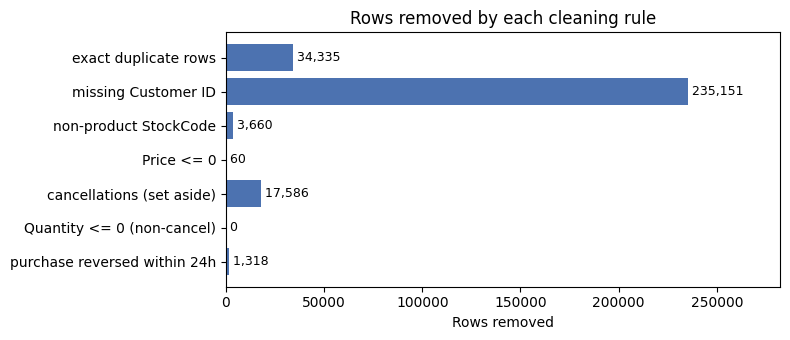

In [11]:
fig, ax = plt.subplots(figsize=(8, 3.5))
steps = log.iloc[1:]
ax.barh(steps["rule"][::-1], steps["rows_removed"][::-1], color="#4C72B0")
for y, v in enumerate(steps["rows_removed"][::-1]):
    ax.text(v, y, f" {v:,}", va="center", fontsize=9)
ax.set_title("Rows removed by each cleaning rule")
ax.set_xlabel("Rows removed")
ax.set_xlim(0, steps["rows_removed"].max() * 1.2)
plt.tight_layout()
plt.show()

**Takeaway:** missing Customer ID dominates row removal (about 235k rows). By row count, every other rule is small.
But row counts hide **value**: the 24h-reversal rule removes relatively few rows and a disproportionate amount of spend, because it targets the biggest erroneous orders.
**Lesson: judge a cleaning rule by its effect on the target, not by its row count.**

## 4. Outliers: inspect, then decide explicitly
Spend is extremely skewed. The question isn't "remove outliers?" but **"are the extreme values real, and what should the model do with them?"**

In [12]:
cust = purchases.groupby("Customer ID").agg(
    total_spend=("Spend", "sum"),
    n_orders=("Invoice", "nunique"),
    country=("Country", "first"),
)
cust["avg_order_value"] = cust["total_spend"] / cust["n_orders"]

print(cust[["total_spend", "n_orders", "avg_order_value"]]
      .describe(percentiles=[.5, .9, .99]).round(0).to_string())
top10 = cust["total_spend"].nlargest(int(len(cust) * 0.10)).sum() / cust["total_spend"].sum()
top1 = cust["total_spend"].nlargest(int(len(cust) * 0.01)).sum() / cust["total_spend"].sum()
print(f"\nTop 10% of customers = {top10:.0%} of spend;  top 1% = {top1:.0%}")
print(f"One-time buyers (1 invoice ever): {(cust['n_orders'] == 1).mean():.0%}")

       total_spend  n_orders  avg_order_value
count       5851.0    5851.0           5851.0
mean        2857.0       6.0            366.0
std        13999.0      13.0            546.0
min            3.0       1.0              3.0
50%          854.0       3.0            277.0
90%         5360.0      13.0            624.0
99%        27064.0      46.0           1861.0
max       579705.0     371.0          19810.0

Top 10% of customers = 63% of spend;  top 1% = 31%
One-time buyers (1 invoice ever): 28%


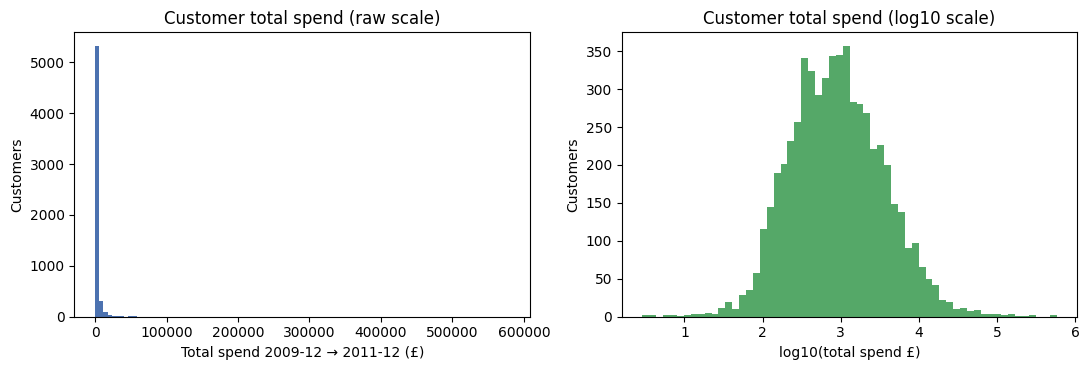

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(cust["total_spend"], bins=100, color="#4C72B0")
axes[0].set_title("Customer total spend (raw scale)")
axes[0].set_xlabel("Total spend 2009-12 → 2011-12 (£)")
axes[0].set_ylabel("Customers")

axes[1].hist(np.log10(cust["total_spend"]), bins=60, color="#55A868")
axes[1].set_title("Customer total spend (log10 scale)")
axes[1].set_xlabel("log10(total spend £)")
axes[1].set_ylabel("Customers")
plt.tight_layout()
plt.show()

**Takeaway:** on a raw scale the histogram is a single spike at zero with an invisible tail. On a log scale it's roughly bell-shaped, centred around £1k.
Spend is roughly **log-normal**, which already hints at modelling choices (log1p target, Tweedie loss) for notebook 07.

In [14]:
cust.nlargest(10, "total_spend").round(0)

,total_spend,n_orders,country,avg_order_value
Customer ID,,,,
18102,579705.0,145,United Kingdom,3998.0
14646,526752.0,145,Netherlands,3633.0
14156,302925.0,144,EIRE,2104.0
14911,264120.0,371,EIRE,712.0
17450,234634.0,50,United Kingdom,4693.0
13694,194678.0,142,United Kingdom,1371.0
17511,169627.0,59,United Kingdom,2875.0
16684,144130.0,54,United Kingdom,2669.0
12415,143875.0,23,Australia,6255.0


**Decision: keep the big customers in the data. Handle the tail in modelling, not in cleaning.**
- These look like **genuine wholesale accounts** (many orders over two years, not a single freak line). The freak single lines were already removed by the reversal rule.
- **Why not drop them:** the top 1% are a large share of revenue. They are exactly the customers the business most needs to predict well. Dropping them makes the metrics look better and the model less useful.
- **Why not cap the raw data:** capping changes the *target*. If capping is needed, it belongs in **feature preprocessing** (notebook 05) and as a **model/loss choice** (log1p, Tweedie) in notebook 07, where it can be compared honestly.
- **What we'll do instead:** flag wholesale-like customers as a feature, and break down errors by segment (big vs. small buyers) in notebook 12.

## 5. Sanity checks and save

In [15]:
assert purchases["Customer ID"].notna().all()
assert (purchases["Quantity"] > 0).all() and (purchases["Price"] > 0).all()
assert not is_cancellation(purchases["Invoice"]).any()
assert not is_non_product(purchases["StockCode"]).any()
assert not purchases.duplicated().any()
assert (returns["ReturnValue"] > 0).all()
print("All checks passed.")

purchases.to_parquet(CLEAN_PARQUET, index=False)
returns.to_parquet(RETURNS_PARQUET, index=False)
print(f"Saved {len(purchases):,} purchase lines → {CLEAN_PARQUET.name}")
print(f"Saved {len(returns):,} return lines   → {RETURNS_PARQUET.name}")

All checks passed.


Saved 775,261 purchase lines → transactions_clean.parquet
Saved 16,268 return lines   → returns_clean.parquet


## 6. What this means for the rest of the project

| Finding | Implication downstream |
|---|---|
| ~5.9k identified customers; anonymous buyers dropped | Results describe **account holders** and overstate retention vs. the full customer base. State this in notebook 12. |
| Spend roughly log-normal, top 10% ≈ two-thirds of revenue | MAE/RMSE will be dominated by a few customers, so also report **rank metrics** (Spearman, decile lift). Compare log1p vs. Tweedie vs. hurdle (07). |
| About a quarter of customers bought only once | Lots of next-6-month zeros: `y_buy` matters, and `y_spend` is zero-inflated. |
| Returns kept as a separate table | Return-rate feature in notebook 04. Must use **only returns on or before the cutoff**. |
| Entry-error reversals removed | Without this, two typos would have been the largest "purchases" in the data. |

### 🧠 Interpret (answer in your own words)
1. Your earlier prediction: which rule removed the most rows, and which mattered most for **spend**? Were they the same rule? Why not?
2. A stakeholder asks: *"Why didn't you just remove outliers above the 99th percentile?"* Give a 2-sentence answer.
3. We netted out same-day reversals but **not** later returns. Construct a concrete example where netting a later return would leak future information into a feature at a cutoff date.
4. At ARQ, what's the analogue of an "entry-error reversal"? (Think: failed or reversed card transactions, FX conversions undone within minutes.) Would you count them as activity?